<table border=0 width="100%"><tr><td><font size=5><B>week04-homework-api-data</B></font></td></tr></table>

# 第四周作业：选择1家上市公司并结合tushare获取数据进行分析
- 自由选择1家感兴趣的上市公司；
- 针对你选择的公司，提出一个你感兴趣的问题；
- 应用tushare获取与该公司相关的数据（不限于股市价格数据、财务等数据，国家宏观等数据均可使用）；
- 尝试应用你采集的数据做数据分析，回答你提出的问题。


提交作业：
- 在线提交：http://swufe.fanya.chaoxing.com/portal
- 截止日期：2026年10月16日晚上8点
- 提交**这个jupyter文档**，命名为“week04-homework-api-data_学号_姓名.ipynb”，学号姓名替换为自己的学号和姓名
- jupyter文档你要完成的包括四部分：公司名称与基本简介、研究问题题目及其内涵介绍、数据采集、数据分析与问题解答
- 为了批改方便，我这里将tushare token直接放到代码中

# 第一部分：公司名称与基本简介

公司名称：比亚迪股份有限公司（BYD Company Limited）
A股代码：002594.SZ；H股代码：01211.HK

主营业务：公司业务由三大板块构成——1. 汽车、汽车相关产品及其他产品业务（核心，贡献约八成营收）：以新能源汽车（纯电 BEV + 插电混动 DM）为主，覆盖王朝网、海洋网两大主销网络，以及腾势、方程豹、仰望三大高端品牌；同时布局动力电池（刀片电池）、半导体（IGBT/碳化硅）、车规级芯片与整车平台技术。
2. 手机部件、组装及其他产品业务（第二大板块）：为全球头部消费电子品牌提供结构件、组装及新型智能产品服务。
3. 二次充电电池及光伏业务：消费类锂电池、储能系统与光伏组件。

行业地位：公司是全球新能源汽车销量第一的车企，也是全球唯一同时掌握电池、电机、电控、芯片等新能源汽车核心零部件的整车企业，垂直整合程度业内最高。2025 年公司营业总收入 8,039.65 亿元，归母净利润 326.19 亿元。

# 第二部分：研究问题题目及其内涵介绍

研究问题：比亚迪近十年（2015—2025）的"高增长"是否等于"高质量"？
内涵介绍：过去十年，比亚迪的营收从 800 亿元增长到 8,040 亿元，是 A 股最典型的高成长故事。但"增长快"并不等于"增长好"：如果增长靠的是补贴、压货、拉长应付账期或持续加杠杆，那么这种增长就缺乏持续性，一旦行业景气回落就会迅速失速。因此本问题需要把"增长"拆成两个层面来检验：
1. 成长性（增长有多快、从哪来）
营收与归母净利润的十年增速与复合增长率（CAGR）；
成长的节奏：是一路平稳上行，还是"两段式"（先低估后爆发）？爆发依赖什么？
增长的来源：量增还是价增、内生还是外延、行业景气还是份额提升。

2. 盈利质量（增长赚到的钱是否真实、是否可持续）
盈利水平：毛利率、净利率、加权 ROE 的长期趋势，是同步改善还是"增收不增利"；
收益的现金含量：经营活动现金流净额 / 归母净利润（净现比），衡量利润是否有真金白银支撑；
收益的纯净度：扣非归母净利润 / 归母净利润，衡量利润有多少来自政府补助、投资收益等非经常性损益；
增长的可持续性来源：研发投入规模与研发强度，判断增长是"补贴驱动"还是"技术驱动"；

# 第三部分：数据采集

In [2]:
import tushare as ts
# 为了批改方便，我这里将tushare token直接放到代码中
token = "5c426f5af978fd42fe0f81fe7e60c02ada33d6c79347b61ccb44f521"
ts.set_token(token=token)
pro = ts.pro_api()

In [3]:
!pip install tushare pandas numpy matplotlib -q
import tushare as ts
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

token = "5c426f5af978fd42fe0f81fe7e60c02ada33d6c79347b61ccb44f521"
ts.set_token(token=token)
pro = ts.pro_api()

BASE = "outputs"
DATA_DIR = BASE + "/data"
CHART_DIR = BASE + "/charts"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(CHART_DIR, exist_ok=True)
            
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 130
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

CODE = "002594.SZ"          # 比亚迪 A 股
START, END = "20140101", "20261231"
RED, GREEN, BLUE, ORANGE, GREY = "#d62728", "#2ca02c", "#1f77b4", "#ff7f0e", "#7f7f7f"
print("tushare 版本:", ts.__version__)



tushare 版本: 1.4.29


In [19]:
basic = pro.stock_basic(ts_code=CODE,
                        fields="ts_code,symbol,name,area,industry,market,list_date,fullname")
basic.to_csv(DATA_DIR + "/company_basic.csv", index=False, encoding="utf-8-sig")
basic

,ts_code,symbol,name,area,industry,market,list_date,fullname
0,002594.SZ,002594,比亚迪,深圳,汽车整车,主板,20110630,比亚迪股份有限公司


In [20]:
#利润表
income = pro.income(ts_code=CODE, start_date=START, end_date=END, report_type="1")
income = income.drop_duplicates(subset=["end_date"], keep="first").sort_values("end_date")
income = income[income["end_date"].str.endswith(("1231", "0630"))]
income.to_csv(DATA_DIR + "/income.csv", index=False, encoding="utf-8-sig")
income[["end_date", "revenue", "oper_cost", "n_income_attr_p", "rd_exp",
        "operate_profit", "total_profit", "n_income"]].tail(14)

,end_date,revenue,oper_cost,n_income_attr_p,rd_exp,operate_profit,total_profit,n_income
35,20191231,1.277385e+11,1.069243e+11,1.614450e+09,5.629372e+09,2.312288e+09,2.431131e+09,2.118857e+09
31,20200630,6.050299e+10,4.864668e+10,1.662430e+09,2.525361e+09,2.948123e+09,2.928081e+09,2.383423e+09
27,20201231,1.565977e+11,1.262514e+11,4.234267e+09,7.464861e+09,7.085773e+09,6.882587e+09,6.013963e+09
25,20210630,9.088540e+10,7.928492e+10,1.173571e+09,2.995687e+09,2.216240e+09,2.204115e+09,1.810771e+09
22,20211231,2.161424e+11,1.879977e+11,3.045188e+09,7.990974e+09,4.631992e+09,4.518003e+09,3.967266e+09
19,20220630,1.506073e+11,1.302655e+11,3.595279e+09,5.424256e+09,4.622116e+09,4.641481e+09,3.933136e+09
16,20221231,4.240606e+11,3.518157e+11,1.662245e+10,1.865445e+10,2.154182e+10,2.107973e+10,1.771310e+10
14,20230630,2.601241e+11,2.124516e+11,1.095414e+10,1.383465e+10,1.373128e+10,1.339992e+10,1.143972e+10
12,20231231,6.023154e+11,4.805584e+11,3.004081e+10,3.957494e+10,3.810310e+10,3.726864e+10,3.134407e+10
10,20240630,3.011267e+11,2.408600e+11,1.363126e+10,1.962076e+10,1.732328e+10,1.722814e+10,1.411322e+10


In [21]:
#财务指标（毛利率、净利率、ROE、扣非净利润等）
fina = pro.fina_indicator(ts_code=CODE, start_date=START, end_date=END)
fina = fina.drop_duplicates(subset=["end_date"], keep="first").sort_values("end_date")
fina = fina[fina["end_date"].str.endswith(("1231", "0630"))]
fina.to_csv(DATA_DIR + "/fina_indicator.csv", index=False, encoding="utf-8-sig")
fina[["end_date", "eps", "profit_dedt", "grossprofit_margin", "netprofit_margin",
      "roe", "roe_waa", "debt_to_assets", "current_ratio", "quick_ratio"]].tail(14)

,end_date,eps,profit_dedt,grossprofit_margin,netprofit_margin,roe,roe_waa,debt_to_assets,current_ratio,quick_ratio
40,20191231,0.50,2.305060e+08,16.2944,1.6587,2.8840,2.62,68.0020,0.9902,0.7535
36,20200630,0.56,9.162270e+08,19.5962,3.9393,2.8493,2.84,65.9917,1.0739,0.7997
32,20201231,1.47,2.953923e+09,19.3785,3.8404,7.4523,7.43,67.9361,1.0486,0.7536
28,20210630,0.41,3.686660e+08,12.7639,1.9924,1.6992,1.50,59.9429,1.1491,0.7960
24,20211231,1.06,1.254619e+09,13.0214,1.8355,4.0083,3.73,64.7562,0.9697,0.7166
20,20220630,1.24,3.029410e+09,13.5065,2.6115,3.7514,3.75,69.2897,0.8377,0.5751
16,20221231,5.71,1.563779e+10,17.0365,4.1770,16.1305,16.14,75.4202,0.7224,0.4851
13,20230630,3.77,9.694855e+09,18.3269,4.3978,9.4967,9.36,77.9405,0.6589,0.4437
11,20231231,10.32,2.846243e+10,20.2148,5.2039,24.0481,24.40,77.8585,0.6660,0.4727
9,20240630,4.68,1.231541e+10,20.0137,4.6868,9.6814,9.67,77.4700,0.6592,0.4101


In [22]:
#现金流量表
cashflow = pro.cashflow(ts_code=CODE, start_date=START, end_date=END, report_type="1")
cashflow = cashflow.drop_duplicates(subset=["end_date"], keep="first").sort_values("end_date")
cashflow = cashflow[cashflow["end_date"].str.endswith(("1231", "0630"))]
cashflow.to_csv(DATA_DIR + "/cashflow.csv", index=False, encoding="utf-8-sig")
cashflow[["end_date", "n_cashflow_act", "n_cashflow_inv_act", "n_cash_flows_fnc_act",
          "c_fr_sale_sg"]].tail(14)

,end_date,n_cashflow_act,n_cashflow_inv_act,n_cash_flows_fnc_act,c_fr_sale_sg
40,20191231,1.474101e+10,-2.088145e+10,6.610345e+09,1.071661e+11
37,20200630,1.553845e+10,-6.912217e+09,-7.558569e+09,5.522439e+10
34,20201231,4.539267e+10,-1.444425e+10,-2.890742e+10,1.386669e+11
32,20210630,9.676845e+09,-1.291883e+10,1.063952e+10,7.162677e+10
29,20211231,6.546668e+10,-4.540399e+10,1.606252e+10,2.026665e+11
26,20220630,4.318517e+10,-4.280756e+10,-9.002326e+09,1.528375e+11
23,20221231,1.408377e+11,-1.205960e+11,-1.948868e+10,4.132092e+11
20,20230630,8.197118e+10,-5.853627e+10,4.050212e+09,2.513138e+11
17,20231231,1.697250e+11,-1.256636e+11,1.281713e+10,5.727048e+11
13,20240630,1.417831e+10,-5.587408e+10,-1.235842e+10,2.970838e+11


In [23]:
#资产负债表
balance = pro.balancesheet(ts_code=CODE, start_date=START, end_date=END, report_type="1")
balance = balance.drop_duplicates(subset=["end_date"], keep="first").sort_values("end_date")
balance = balance[balance["end_date"].str.endswith(("1231", "0630"))]
balance.to_csv(DATA_DIR + "/balancesheet.csv", index=False, encoding="utf-8-sig")
balance[["end_date", "total_assets", "total_liab", "total_hldr_eqy_exc_min_int",
         "total_cur_assets", "total_cur_liab"]].tail(14)

,end_date,total_assets,total_liab,total_hldr_eqy_exc_min_int,total_cur_assets,total_cur_liab
42,20191231,1.956416e+11,1.330402e+11,5.676229e+10,1.069666e+11,1.080289e+11
39,20200630,1.976364e+11,1.304235e+11,5.992823e+10,1.088496e+11,1.013617e+11
36,20201231,2.010173e+11,1.365634e+11,5.687427e+10,1.116051e+11,1.064307e+11
33,20210630,2.228945e+11,1.336094e+11,8.125504e+10,1.291728e+11,1.124169e+11
29,20211231,2.957801e+11,1.915359e+11,9.506967e+10,1.661102e+11,1.713039e+11
26,20220630,3.459429e+11,2.397026e+11,9.660904e+10,1.825686e+11,2.179300e+11
22,20221231,4.938606e+11,3.724708e+11,1.110293e+11,2.408035e+11,3.333446e+11
18,20230630,5.911334e+11,4.607323e+11,1.196655e+11,2.660071e+11,4.036896e+11
15,20231231,6.795477e+11,5.290856e+11,1.388101e+11,3.021214e+11,4.536667e+11
12,20240630,6.862447e+11,5.316336e+11,1.427872e+11,2.984316e+11,4.527428e+11


In [24]:
#宏观背景数据（GDP，用于判断增长是否只是宏观顺风）
gdp = pro.cn_gdp(start_date="20150101", end_date=END)
gdp.to_csv(DATA_DIR + "/cn_gdp.csv", index=False, encoding="utf-8-sig")
gdp.head(6)

,quarter,gdp,gdp_yoy,pi,pi_yoy,si,si_yoy,ti,ti_yoy
0,2026Q2,695704.0,4.7,31521.8,3.7,250472.9,3.9,413709.2,5.2
1,2026Q1,334192.9,5.0,11940.8,3.8,116134.9,4.9,206117.2,5.2
2,2025Q4,1401879.2,5.0,93346.8,3.9,499653.0,4.5,808879.3,5.4
3,2025Q3,1013967.9,5.2,58187.1,3.8,362849.7,4.9,592931.1,5.4
4,2025Q2,659861.6,5.3,31234.8,3.7,238262.6,5.3,390364.3,5.5
5,2025Q1,318466.4,5.4,11729.8,3.5,111549.3,5.9,195187.3,5.3


In [25]:
#组装"年度 + 半年度"核心指标总表
def val(df, col, period):
    d = df[df["end_date"] == period]
    return np.nan if d.empty else d.iloc[0][col]

periods = sorted(set(income["end_date"]) | set(fina["end_date"]), reverse=True)
recs = []
for p in periods:
    recs.append({
        "end_date": p,
        "revenue": val(income, "revenue", p),
        "n_income_attr_p": val(income, "n_income_attr_p", p),
        "rd_exp": val(income, "rd_exp", p),
        "profit_dedt": val(fina, "profit_dedt", p),
        "gross_margin": val(fina, "grossprofit_margin", p),
        "net_margin": val(fina, "netprofit_margin", p),
        "roe": val(fina, "roe", p),
        "roe_waa": val(fina, "roe_waa", p),
        "ocf": val(cashflow, "n_cashflow_act", p),
        "total_assets": val(balance, "total_assets", p),
        "total_liab": val(balance, "total_liab", p),
        "equity": val(balance, "total_hldr_eqy_exc_min_int", p),
    })
m = pd.DataFrame(recs).sort_values("end_date").reset_index(drop=True)
m["year"] = m["end_date"].str[:4].astype(int)
m["ptype"] = np.where(m["end_date"].str.endswith("1231"), "annual", "h1")

for c in ["revenue", "n_income_attr_p", "profit_dedt", "rd_exp", "ocf",
          "total_assets", "total_liab", "equity"]:
    m[c + "_亿"] = m[c] / 1e8

# 同一报告期内计算同比（年报比年报、半年报比半年报）
m["rev_yoy"] = m.groupby("ptype")["revenue"].transform(lambda s: (s / s.shift(1) - 1) * 100)
m["ni_yoy"] = m.groupby("ptype")["n_income_attr_p"].transform(lambda s: (s / s.shift(1) - 1) * 100)
m["ocf_ni"] = m["ocf"] / m["n_income_attr_p"]                  # 净现比
m["dedt_ratio"] = m["profit_dedt"] / m["n_income_attr_p"] * 100 # 扣非占比
m["rd_intensity"] = m["rd_exp"] / m["revenue"] * 100            # 研发强度
m["debt_ratio"] = m["total_liab"] / m["total_assets"] * 100     # 资产负债率
m["equity_mult"] = m["total_assets"] / m["equity"]              # 权益乘数
m["asset_turn"] = m["revenue"] / m["total_assets"]              # 总资产周转率

m.to_csv(DATA_DIR + "/annual_metrics.csv", index=False, encoding="utf-8-sig")
show = ["end_date", "revenue_亿", "rev_yoy", "n_income_attr_p_亿", "ni_yoy", "profit_dedt_亿",
        "gross_margin", "net_margin", "roe_waa", "ocf_亿", "ocf_ni", "dedt_ratio",
        "rd_exp_亿", "rd_intensity", "debt_ratio", "equity_mult", "asset_turn"]
m[m["year"] >= 2015][show].round(2).reset_index(drop=True)

,end_date,revenue_亿,rev_yoy,n_income_attr_p_亿,ni_yoy,profit_dedt_亿,gross_margin,net_margin,roe_waa,ocf_亿,ocf_ni,dedt_ratio,rd_exp_亿,rd_intensity,debt_ratio,equity_mult,asset_turn
0,20150630,315.82,18.22,4.67,29.38,1.52,17.44,1.98,1.82,30.22,6.48,32.67,NaN,NaN,69.11,3.69,0.33
1,20151231,800.09,37.48,28.23,551.28,12.07,16.87,3.92,10.22,38.42,1.36,42.74,NaN,NaN,68.80,3.58,0.69
2,20160630,449.50,42.32,22.60,384.23,20.67,20.83,5.49,7.14,-14.28,-0.63,91.47,NaN,NaN,68.14,3.50,0.37
3,20161231,1034.70,29.32,50.52,78.94,46.13,20.36,5.30,12.91,-18.46,-0.37,91.32,NaN,NaN,61.81,2.83,0.71
4,20170630,450.38,0.20,17.23,-23.75,11.16,20.32,4.81,3.33,-34.70,-2.01,64.75,NaN,NaN,62.81,2.92,0.29
5,20171231,1059.15,2.36,40.66,-19.51,29.87,19.01,4.64,7.76,63.68,1.57,73.45,NaN,NaN,66.33,3.24,0.59
6,20180630,541.51,20.23,4.79,-72.19,-6.73,15.92,1.61,0.71,-16.07,-3.35,-140.51,20.79,3.84,68.97,3.53,0.28
7,20181231,1300.55,22.79,27.80,-31.63,5.86,16.40,2.73,4.96,125.23,4.50,21.06,49.89,3.84,68.81,3.52,0.67
8,20190630,621.84,14.84,14.55,203.61,7.40,17.14,2.65,2.58,-20.65,-1.42,50.90,24.95,4.01,68.87,3.53,0.31
9,20191231,1277.39,-1.78,16.14,-41.93,2.31,16.29,1.66,2.62,147.41,9.13,14.28,56.29,4.41,68.00,3.45,0.65


# 第四部分：数据分析过程

In [26]:
#先计算十年复合增长率（CAGR），再看逐年增速的节奏。

ann = m[(m["ptype"] == "annual") & (m["year"] >= 2015)].copy().reset_index(drop=True)

def cagr(first, last, years):
    return ((last / first) ** (1 / years) - 1) * 100

n = len(ann) - 1
print(f"2015—2025（{n} 年）营业总收入 CAGR: {cagr(ann.iloc[0]['revenue'], ann.iloc[-1]['revenue'], n):.2f}%")
print(f"2015—2025（{n} 年）归母净利润 CAGR: {cagr(ann.iloc[0]['n_income_attr_p'], ann.iloc[-1]['n_income_attr_p'], n):.2f}%")

sub = ann[ann["year"] <= 2024].reset_index(drop=True)
n2 = len(sub) - 1
print(f"\n分段① 2015—2024（{n2} 年）营收 CAGR: {cagr(sub.iloc[0]['revenue'], sub.iloc[-1]['revenue'], n2):.2f}%")
print(f"分段① 2015—2024（{n2} 年）归母净利润 CAGR: {cagr(sub.iloc[0]['n_income_attr_p'], sub.iloc[-1]['n_income_attr_p'], n2):.2f}%")

sub2 = ann[ann["year"] >= 2020].reset_index(drop=True)
n3 = len(sub2) - 1
print(f"\n分段② 2020—2024（{n3} 年）营收 CAGR: {cagr(sub2.iloc[0]['revenue'], sub2[sub2.year == 2024].iloc[0]['revenue'], n3):.2f}%")
print(f"分段② 2020—2024（{n3} 年）归母净利润 CAGR: {cagr(sub2.iloc[0]['n_income_attr_p'], sub2[sub2.year == 2024].iloc[0]['n_income_attr_p'], n3):.2f}%")

print("\n近三年（2023—2025）:")
ann[ann["year"] >= 2023][["year", "revenue_亿", "rev_yoy", "n_income_attr_p_亿", "ni_yoy"]].round(2)

2015—2025（10 年）营业总收入 CAGR: 25.95%
2015—2025（10 年）归母净利润 CAGR: 27.72%

分段① 2015—2024（9 年）营收 CAGR: 28.74%
分段① 2015—2024（9 年）归母净利润 CAGR: 34.35%

分段② 2020—2024（5 年）营收 CAGR: 37.76%
分段② 2020—2024（5 年）归母净利润 CAGR: 56.89%

近三年（2023—2025）:


,year,revenue_亿,rev_yoy,n_income_attr_p_亿,ni_yoy
8,2023,6023.15,42.04,300.41,80.72
9,2024,7771.02,29.02,402.54,34.00
10,2025,8039.65,3.46,326.19,-18.97


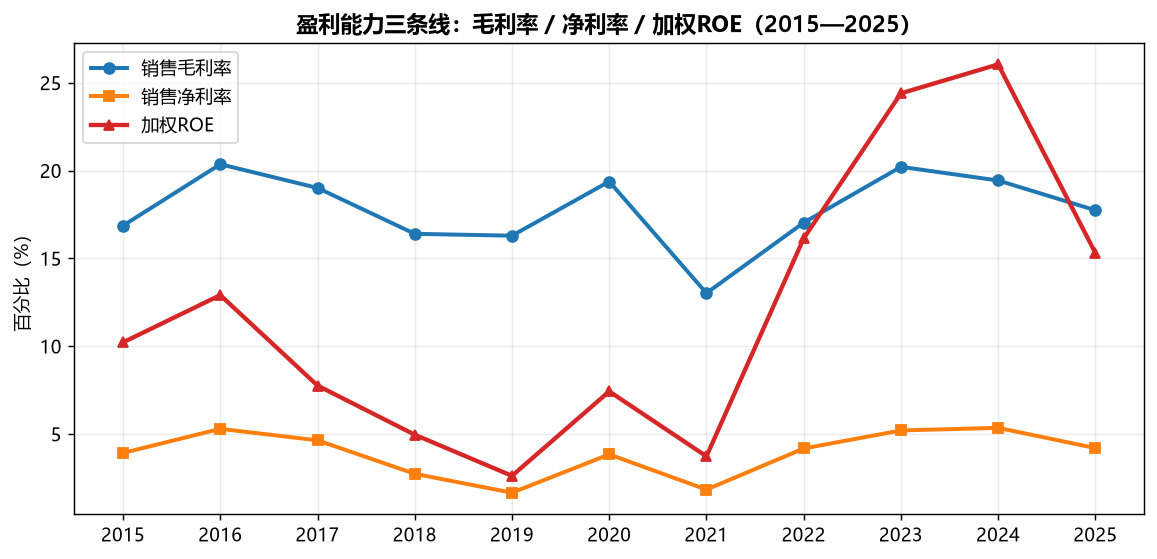

已保存 fig3_profitability.png


In [27]:
#盈利能力：利润率与 ROE 是否与规模同步提升
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.plot(ann["year"].astype(str), ann["gross_margin"], color=BLUE, marker="o", lw=2.2, label="销售毛利率")
ax.plot(ann["year"].astype(str), ann["net_margin"], color=ORANGE, marker="s", lw=2.2, label="销售净利率")
ax.plot(ann["year"].astype(str), ann["roe_waa"], color=RED, marker="^", lw=2.4, label="加权ROE")
ax.set_ylabel("百分比（%）")
ax.set_title("盈利能力三条线：毛利率 / 净利率 / 加权ROE（2015—2025）", fontsize=12, fontweight="bold")
ax.legend(); ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(CHART_DIR + "/fig3_profitability.png", bbox_inches="tight")
plt.show()
print("已保存 fig3_profitability.png")

# 第五部分：研究结论与经验总结

## 研究结论

比亚迪近十年的"高增长"是否等于"高质量"？——答案是"一半是，一半不是"，且质量随阶段大幅波动。

结论一：成长性很高，但"高增长"在时间上极不均匀，用平均值描述会失真
2015—2025 年营收 CAGR 25.95%、归母净利润 CAGR 27.72%，总量看无愧"十年十倍"。但增长集中在 2020—2024 年（营收 CAGR 约 49%、归母净利润 CAGR 约 76%），2015—2019 年营收 CAGR 仅约 12.4%、利润反而从 28.23 亿元降至 16.14 亿元。2025 年起增速断崖：营收 +3.46%、归母净利润 -18.97%；2026 中报营收 -7.13%、归母净利润 -20.54%。

结论二：增长质量的分层判断——"中间年份优、头尾两年弱"
质量最好的三年：2022—2024。营收 CAGR 约 35%（4,240→7,771 亿元），毛利率稳定在 17%—20%，加权 ROE 16%→26%，扣非占比 92%—95%，规模效应与垂直整合真正转化为利润，同时现金流充沛。
质量最差的两年：2018—2019。营收停滞（2019 年 -1.78%），归母净利润 27.80→16.14 亿元，扣非净利润仅 5.86→2.31 亿元，扣非占比 21%/14%，利润几乎靠补贴与非经常性损益维持。
当前处于"换挡期"：营收与利润双降，但毛利率回升、现金含量改善、研发强度创历史新高，属于"用短期利润换长期质量"的阶段，风险在于这种转型能否在竞争加剧的环境中兑现。

结论三：对问题的直接回答与风险提示
直接回答：比亚迪的"高增长"包含了真实的高质量内核（现金流扎实、研发高强度、规模效应真实兑现），但并非全程高质量——它经历了"补贴依赖期（2015—2019）—真质量兑现期（2022—2024）—转型验证期（2025 至今）"三个阶段；且当前的 ROE 水平部分依赖高杠杆，增长的质量仍需未来 2—3 年验证。
最需要跟踪的三个风险：1.国内价格战持续压制净利率（净利率一旦跌破 3%，ROE 与现金流将同步承压）；2.高杠杆 + 负营运资本带来的流动性压力（2026 中报流动比率 0.87、速动比率 0.49）；3.研发与资本开支能否持续维持高强度（2026 年中报研发同比已回落）。


## 经验总结

1. "增长快"和"增长好"是两件事。最开始我直觉认为营收十倍增长就是好公司，但把数据摊开后发现：如果只看营收，会漏掉 2019 年"利润只剩 16 亿元、扣非只有 2.31 亿元"的真相。分析增长必须同时看利润、现金流、扣非利润三条线。
2. 同比一定要对齐口径。第一次写代码时我用 `pct_change()` 直接算，结果半年报和年报混在一起，算出了"+158%"这种明显错误的增速（实际上是把半年报和年报相比）。修正办法是先把年报和半年报分组，再组内做同比。
3. tushare 的日期过滤是"公告日"不是"报告期"。用 `start_date`/`end_date` 过滤时，2025 年年报（2026 年 3 月公告）会被漏掉；改用 `period="20251231"` 参数才能稳定取到指定报告期。